In [1]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os

from specula.mmlib.yaml_overrides import write_yaml_overrides
from specula.mmlib.compute_rec import compute_and_save_rec

2026-11-02 12:31:37,064 [INFO]: [specula]: Cupy import successfull. Installed version is: 13.3.0
2026-11-02 12:31:44,944 [INFO]: [specula]: Default device is GPU number 0


In [2]:
import matplotlib as mpl
from cycler import cycler

cmap = mpl.colormaps['hot'] # 1. Choose your colormap (e.g., 'hot', 'jet', 'turbo')
colors = cmap(np.linspace(0.0, 1.0, 7)) # 2. Extract a set of colors from it (e.g., 6 distinct colors across the map)
# plt.rcParams['axes.prop_cycle'] = cycler(color=colors) # 3. Apply it to the default line cycle
plt.rcParams['image.cmap'] = 'magma' # 4. Change the default colormap for images/scatter plots
plt.rcParams.update({
    "text.usetex": True, # Use LaTeX to write all text
    "font.family": "serif", # Use a serif font
    "font.serif": ["Computer Modern Roman"] # Specifically use the classic LaTeX font
})
plt.rcParams['image.origin'] = 'lower'

In [ ]:
calib_dir = '/raid1/mmenessini/calibration/WFSW'
result_dir = '/raid1/mmenessini/results/WFSW'

In [6]:
# N = 1300
# nSubap = 48
# for wvl in wvls:
#     for rMod in rMods:
#         tag = f'pyr{rMod:1.1f}_{nSubap:1.0f}x{nSubap:1.0f}_wvl{wvl:1.0f}_bmc2k_vlt'
#         im_tag = tag+'_im'
#         # im = fits.getdata(os.path.join(calib_dir,'im',im_tag+'.fits'),1)
#         rec_tag = tag+f'_{N:1.0f}modes_rec'
#         compute_and_save_rec(root_dir=calib_dir, im_tag=im_tag, rec_tag=rec_tag, Nmodes=N)

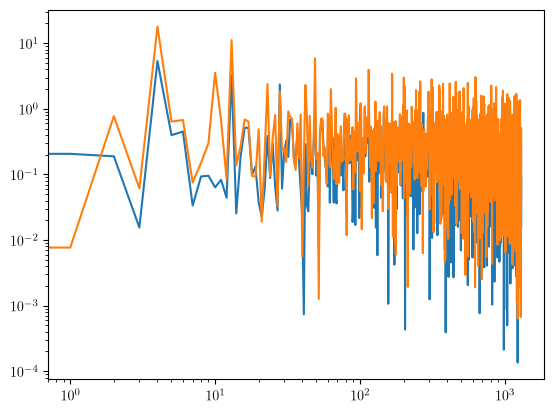

In [41]:
measv = fits.getdata(os.path.join(result_dir,'20261102_130403','meas_vis.fits'))
measr = fits.getdata(os.path.join(result_dir,'20261102_130403','meas_nir.fits'))
modes = fits.getdata(os.path.join(result_dir,'20261102_130403','res.fits'))

plt.figure()
plt.loglog(abs(np.mean(measv,axis=0)))
plt.loglog(abs(np.mean(measr,axis=0)))
# plt.plot(modes[:,1299])

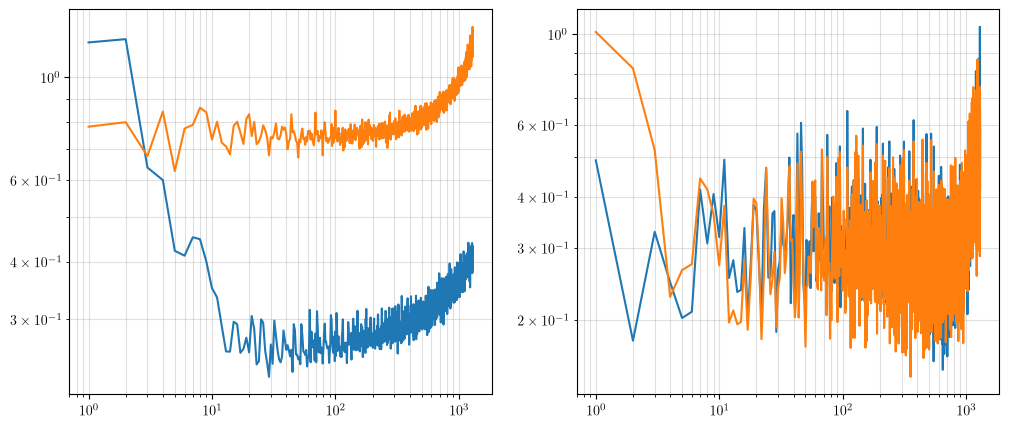

In [52]:
noisev = fits.getdata(os.path.join(result_dir,'20261102_153311','noise_vis.fits'))
noiser = fits.getdata(os.path.join(result_dir,'20261102_153311','noise_nir.fits'))
sigv = fits.getdata(os.path.join(result_dir,'20261102_153311','sig_vis.fits'))
sigr = fits.getdata(os.path.join(result_dir,'20261102_153311','sig_nir.fits'))
x = np.arange(1300)+1

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.loglog(x,np.std(noisev,axis=0))
plt.loglog(x,np.std(noiser,axis=0))
plt.grid(which='both',alpha=0.4)
plt.subplot(1,2,2)
plt.loglog(x,np.std(sigr,axis=0))
plt.loglog(x,np.std(sigv,axis=0))
plt.grid(which='both',alpha=0.4)

(129,) (129, 1300)


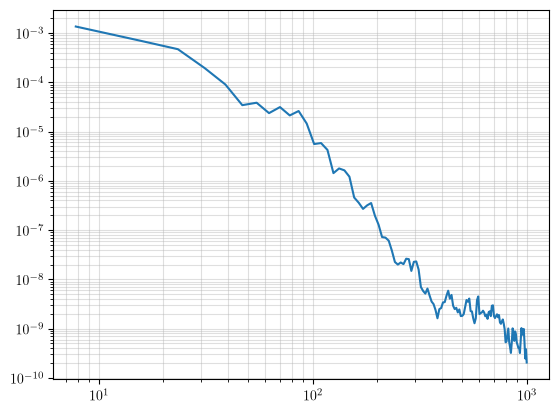

In [ ]:
from scipy.signal import welch
f,psd = welch(sigv,fs=500,axis=0)
f,psd = welch(sigr,fs=2000,axis=0)
print(f.shape,psd.shape)

idxes = [1,10,100,1000]
plt.figure()
for idx in idxes:
    plt.loglog(f[1:],psd[1:,idx])
plt.grid(which='both',alpha=0.4)

(500, 120, 120)


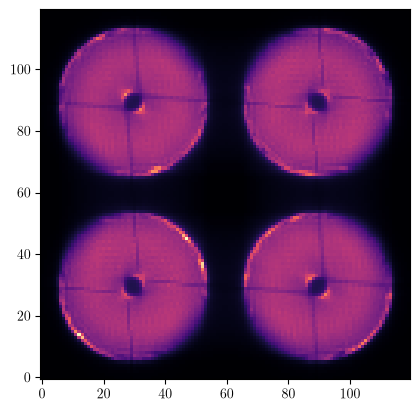

In [16]:
frames = fits.getdata(os.path.join(result_dir,'20261102_130403','vis_frames.fits'))
print(frames.shape)

plt.figure()
plt.imshow(np.median(frames,axis=0))

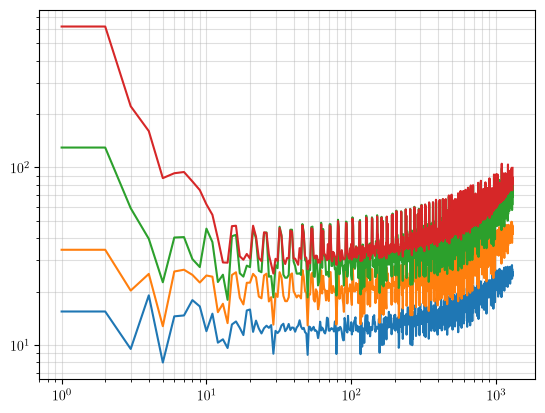

In [7]:
rec0 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)#*(900/1300)
rec05 = fits.getdata(os.path.join(calib_dir,'rec','pyr0.5_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)
rec1 = fits.getdata(os.path.join(calib_dir,'rec','pyr1.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)
rec2 = fits.getdata(os.path.join(calib_dir,'rec','pyr2.0_48x48_wvl1300_bmc2k_vlt_1300modes_rec.fits'),1)

plt.figure()
plt.loglog(np.arange(rec0.shape[0])+1,np.diag(rec0 @ rec0.T))
plt.loglog(np.arange(rec05.shape[0])+1,np.diag(rec05 @ rec05.T))
plt.loglog(np.arange(rec1.shape[0])+1,np.diag(rec1 @ rec1.T))
plt.loglog(np.arange(rec2.shape[0])+1,np.diag(rec2 @ rec2.T))
plt.grid(which='both',alpha=0.4)

In [8]:
# def rec_covariance(rec,frame,mask,flux=None):
#     if flux is None:
#         flux = np.sum(frame)
#     norm = np.mean(frame[mask.astype(bool)])
#     norm_rec = rec / (norm / flux)
#     rec_cov = norm_rec @ norm_rec.T
#     return np.diag(rec_cov)

# def rec_phot_cov(rec,frame,mask,sn,flux=None):
#     if flux is None:
#         flux = np.sum(frame)
#     norm = np.mean(frame[mask.astype(bool)])
#     phot_noise = np.diag(sn/ (norm / flux))
#     rec_cov = rec @ phot_noise @ rec.T
#     return np.diag(rec_cov)

In [9]:
# wvl = 1300
# rec48x48 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_48x48_wvl{wvl}_bmc2k_vlt_1300modes_rec.fits'),1)
# rec36x36 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_36x36_wvl{wvl}_bmc2k_vlt_800modes_rec.fits'),1)
# rec24x24 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_24x24_wvl{wvl}_bmc2k_vlt_300modes_rec.fits'),1)
# rec14x14 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_14x14_wvl{wvl}_bmc2k_vlt_100modes_rec.fits'),1)
# rec10x10 = fits.getdata(os.path.join(calib_dir,'rec',f'pyr0.0_10x10_wvl{wvl}_bmc2k_vlt_54modes_rec.fits'),1)

# def plot_rec_cov(rec,nSubap:int=48):
#     plt.loglog(np.arange(rec.shape[0])+1,np.diag(rec @ rec.T)*(nSubap**2)/(48**2))

# plt.figure()
# plot_rec_cov(rec48x48,nSubap=48)
# plot_rec_cov(rec36x36,nSubap=36)
# plot_rec_cov(rec24x24,nSubap=24)
# plot_rec_cov(rec14x14,nSubap=14)
# plot_rec_cov(rec10x10,nSubap=10)
# plt.grid(which='both',alpha=0.4)